# Part A
## DDPM from Scratch



## Theoretical Background

### DDPM Recap
A Denoising Diffusion Probabilistic Model (Ho et al., 2020) defines:
- A **forward process** $q(x_t | x_{t-1})$ that gradually adds Gaussian noise.
- A **reverse process** $p_\theta(x_{t-1} | x_t)$ parameterized by a neural network.

The forward process in closed form:
$$q(x_t | x_0) = \mathcal{N}(x_t; \sqrt{\bar{\alpha}_t} x_0, (1 - \bar{\alpha}_t) \mathbf{I})$$

The training objective is to minimize:
$$\mathcal{L}_{\text{simple}} = \mathbb{E}_{t, x_0, \epsilon}\left[ \| \epsilon - \epsilon_\theta(x_t, t) \|^2 \right]$$


---
#  Setup

In [1]:
!pip install torch torchvision matplotlib tqdm einops accelerate diffusers transformers --quiet


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import math
from einops import rearrange
from functools import partial
from collections import namedtuple
from torch.optim import Adam
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cuda


---

In this part you will build a complete, publication-quality DDPM from scratch. The expectations here go significantly beyond a basic noise-add-and-predict pipeline.


## A.1 — Noise Schedules: Comparative Analysis

Implement **both** of the following beta schedules and compare them:

### Linear Schedule (Ho et al., 2020)
$$\beta_t = \beta_{\min} + \frac{t-1}{T-1}(\beta_{\max} - \beta_{\min})$$

### Cosine Schedule (Nichol & Dhariwal, 2021)
$$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \quad f(t) = \cos\left(\frac{t/T + s}{1 + s} \cdot \frac{\pi}{2}\right)^2$$

with offset $s = 0.008$, and $\beta_t = 1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}$, clipped to avoid numerical instability.

**Your tasks:**
1. Implement both schedules.
2. Plot $\beta_t$, $\alpha_t$, and $\bar{\alpha}_t$ for both on the same axes.
3. Plot SNR (signal-to-noise ratio) $= \bar{\alpha}_t / (1 - \bar{\alpha}_t)$ for both.
4. In a markdown cell below, explain: *why does the cosine schedule lead to more uniform SNR transitions, and why does this matter for training stability?*


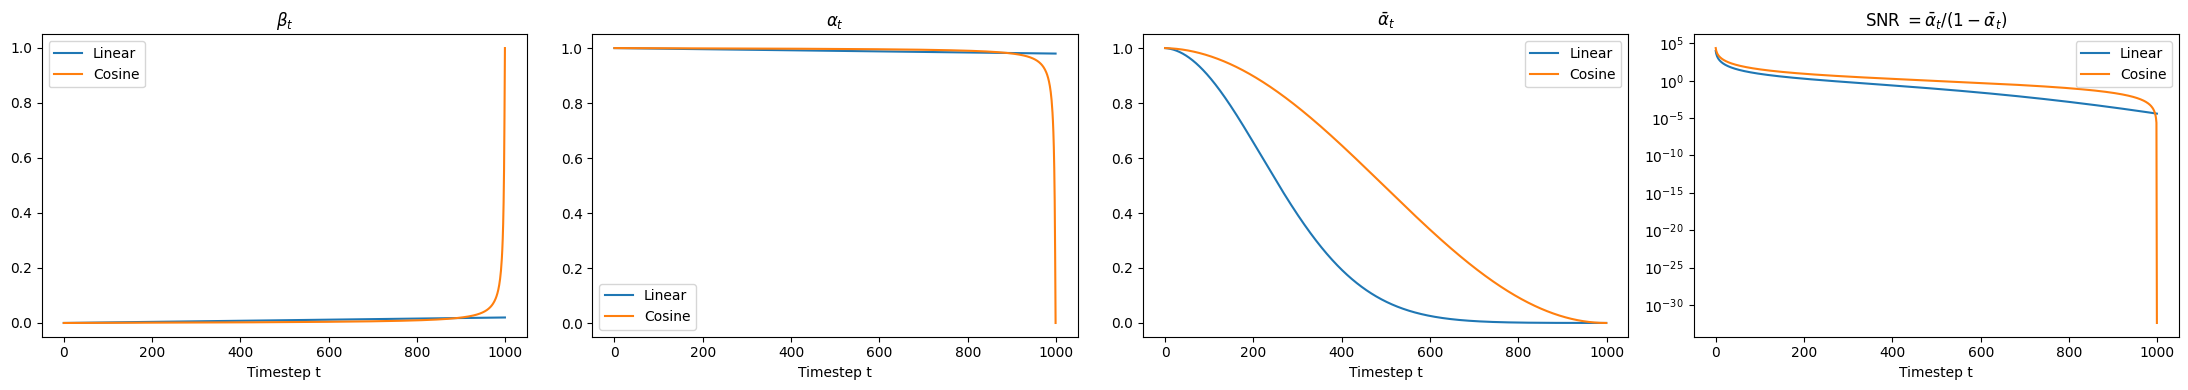

In [3]:
def linear_beta_schedule(T, beta_min=1e-4, beta_max=0.02):
    """
    TODO: Implement the linear beta schedule.
    Returns: betas (T,), alphas (T,), alpha_hats (T,)
    """
    betas = torch.linspace(beta_min, beta_max, T)
    alphas = 1.0 - betas
    alpha_hats = torch.cumprod(alphas, dim=0)
    return betas, alphas, alpha_hats

def cosine_beta_schedule(T, s=0.008):
    """
    TODO: Implement the cosine beta schedule (Nichol & Dhariwal, 2021).
    Clip betas to [0, 0.999] to prevent numerical issues.
    Returns: betas (T,), alphas (T,), alpha_hats (T,)
    """
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps /T) + s) / (1 + s) * (math.pi / 2)) ** 2
    alpha_hats = f/f[0]
    betas = 1.0 -(alpha_hats[1:] / alpha_hats[:-1])
    betas = torch.clamp(betas, 0.0, 0.999).float()
    alpha_hats = alpha_hats[1:].float()
    alphas = 1.0 - betas
    return betas, alphas, alpha_hats

# TODO: Plot the schedules
T_plot = 1000

betas_lin, alphas_lin, alpha_hats_lin = linear_beta_schedule(T_plot)
betas_cos, alphas_cos, alpha_hats_cos = cosine_beta_schedule(T_plot)
timesteps = np.arange(T_plot)
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
axes[0].plot(timesteps, betas_lin.numpy(), label='Linear')
axes[0].plot(timesteps, betas_cos.numpy(), label='Cosine')
axes[0].set_title(r'$\beta_t$')
axes[0].set_xlabel('Timestep t')
axes[0].legend()
axes[1].plot(timesteps, alphas_lin.numpy(), label='Linear')
axes[1].plot(timesteps, alphas_cos.numpy(), label= 'Cosine')
axes[1].set_title(r'$\alpha_t$')
axes[1].set_xlabel('Timestep t')
axes[1].legend()

axes[2].plot(timesteps, alpha_hats_lin.numpy(), label='Linear')
axes[2].plot(timesteps, alpha_hats_cos.numpy(), label='Cosine')
axes[2].set_title(r'$\bar{\alpha}_t$')
axes[2].set_xlabel('Timestep t')
axes[2].legend()

snr_lin = alpha_hats_lin / (1.0 - alpha_hats_lin)
snr_cos = alpha_hats_cos / (1.0 - alpha_hats_cos)
axes[3].plot(timesteps, snr_lin.numpy(), label='Linear')
axes[3].plot(timesteps, snr_cos.numpy(), label='Cosine')
axes[3].set_yscale('log')
axes[3].set_title(r'SNR $= \bar{\alpha}_t / (1 - \bar{\alpha}_t)$')
axes[3].set_xlabel('Timestep t')
axes[3].legend()

plt.tight_layout()
plt.show()

**Your analysis (A.1):** *(Write here)*


the linear schedule increases beta linearly from 1e-4 to 0.02 which causes alpha bar to decay relatively quickly in the early timesteps and then flatten out toward the end as seen in my plots where the li=near alpha bar curve drops steeply through the first 400 steps and is nearly zero by step 600 in contrast the cosine schedule keeps alpha bar high for longer and produces a smooth s-shaped decay that spans the full range of timesteps more evenly
looking at the snr plot on a log scale the linear schedule shows a steep initial drop in snr followed by a long plateau at very low values meaning that a large fraction of timesteps correspond to nearly pure noise where the model receives very little useful gradient signal the cosine schedule on the other hand produces an approximately linear decay in log-snr across the full range of timesteps which means the transitions in signal-to-noise ratio are spread more uniformly
this matters for traianing stability because during training we sample timesteps uniformly at random so if most timesteps have nearly identical snr values as happens with the linear schedule the model wastes capacity learning to distinguish between very similar noise levels and gets fewer meaningful training signals from the informative mid-range timesteps the cosine schedule ensures that each sampled timestep contributes a meaningfully different denoising task which leads to more balanced gradient flow across all noise levels and more stable convrgence as reflected in my smooth loss curve

## A.2 — Forward Process & Posterior

### A.2a — Forward Diffusion
Implement `q_sample(x_0, t, noise=None)` using the closed-form expression:
$$x_t = \sqrt{\bar{\alpha}_t}\, x_0 + \sqrt{1 - \bar{\alpha}_t}\, \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$

Handle batched timesteps correctly (each sample in the batch may have a different $t$).

### A.2b — Posterior Mean & Variance
The reverse posterior $q(x_{t-1} | x_t, x_0)$ is tractable:
$$q(x_{t-1} | x_t, x_0) = \mathcal{N}(x_{t-1}; \tilde{\mu}_t(x_t, x_0),\, \tilde{\beta}_t I)$$

where:
$$\tilde{\mu}_t = \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t} x_0 + \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} x_t$$

$$\tilde{\beta}_t = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \beta_t$$

Implement `q_posterior(x_0, x_t, t)` returning the posterior mean and variance.

**Then answer:** Why can we not directly run the reverse process $q(x_{t-1} | x_t)$ without conditioning on $x_0$? What does this imply about what the network must learn?


In [4]:
T = 1000
# TODO: Choose your preferred schedule and define betas, alphas, alpha_hats, etc.
betas, alphas, alpha_hats = cosine_beta_schedule(T)
sqrt_alpha_hats = torch.sqrt(alpha_hats)
sqrt_one_minus_alpha_hats = torch.sqrt(1.0 - alpha_hats)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
alpha_hats_prev = F.pad(alpha_hats[:-1], (1, 0), value=1.0)
posterior_variance = betas * (1.0 - alpha_hats_prev) / (1.0 - alpha_hats)
posterior_mean_coef1 = (torch.sqrt(alpha_hats_prev) * betas) / (1.0 - alpha_hats)
posterior_mean_coef2 = (torch.sqrt(alphas) * (1.0 - alpha_hats_prev)) / (1.0 - alpha_hats)

def extract(a, t, x_shape):
    """
    Helper: extract values from tensor `a` at indices `t`,
    reshaping for broadcasting with tensors of shape `x_shape`.
    """
    batch_size = t.shape[0]
    out = a.gather(-1, t.cpu())
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1))).to(t.device)

def q_sample(x_0, t, noise=None):
    """
    TODO: Forward diffusion using the reparameterization trick.
    t is a batch of integer timesteps (B,).
    Returns: x_t, noise
    """
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_alpha_hat_t = extract(sqrt_alpha_hats, t, x_0.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t, x_0.shape)
    x_t = sqrt_alpha_hat_t * x_0 + sqrt_one_minus_alpha_hat_t * noise
    return x_t, noise

def q_posterior(x_0, x_t, t):
    """
    TODO: Compute the true posterior mean and variance.
    Returns: posterior_mean, posterior_variance
    """
    coef1 = extract(posterior_mean_coef1, t, x_t.shape)
    coef2 = extract(posterior_mean_coef2, t, x_t.shape)
    mean = coef1 * x_0 + coef2 * x_t
    var = extract(posterior_variance, t, x_t.shape)
    return mean, var

**Your analysis (A.2):** *(Write here)*

disclaimer: i was tired of writign down equations in words so i used aid from AI to covert my picture into math code that shows equations in a markdown clel.


the reverse process $q(x_{t-1} | x_t)$ alone is intractable because it requires marginalizing over all possible clean images $x_0$ which involves computing an integral over the entire data distribution $q(x_{t-1} | x_t) = \int q(x_{t-1} | x_t, x_0) \, q(x_0 | x_t) \, dx_0$ and this integral has no closed form solution however when we condition on $x_0$ the posterior $q(x_{t-1} | x_t, x_0)$ becomes a simple gaussian with analytically computable mean and variance as shown by the formulas for $\tilde{\mu}_t$ and $\tilde{\beta}_t$

this intractability is precisely why we need a neural network in the loop since we cannot compute $q(x_{t-1} | x_t)$ directly the network must learn to approximate it by predicting the noise $\epsilon$ that was added to produce $x_t$ from this predicted noise we can reconstruct an estimate of $x_0$ using $\hat{x}_0 = \frac{1}{\sqrt{\bar{\alpha}_t}}(x_t - \sqrt{1 - \bar{\alpha}_t}\,\epsilon_\theta(x_t, t))$ and then plug that estimate into the tractable posterior formula to obtain the parameters of $p_\theta(x_{t-1} | x_t)$ so in essence the network is indirectly learning to estimate $x_0$ from the noisy observation $x_t$ which is equivalent to learning the score function of the data distribution at each noise level

in my implementation this is exactly what happens during sampling in the p_sample function the model predicts $\epsilon$ we use it to compute the mean of the reverse step via the closed form expression and then add appropriately scaled noise for all steps except the final one

## A.3 — U-Net with Attention & Sinusoidal Embeddings

Build a full U-Net denoiser. Your architecture **must include** all of the following:

1. **Sinusoidal timestep embeddings** — implement the exact embedding from the Transformer paper:  
   $\text{PE}(t, 2i) = \sin(t / 10000^{2i/d})$, $\text{PE}(t, 2i+1) = \cos(t / 10000^{2i/d})$  
   then project through 2 linear layers with a GELU activation.

2. **ResNet blocks** with time conditioning — each block adds a projected time embedding to the intermediate feature maps.

3. **Multi-head self-attention** at the bottleneck (and optionally at intermediate resolutions).

4. **GroupNorm** (not BatchNorm) throughout.

5. **Skip connections** between encoder and decoder stages.

The model takes `(x_t, t)` and outputs predicted noise $\hat{\epsilon}$ of the same shape as $x_t$.

> **Design choice:** You may decide the number of channels, depth, and attention resolution. Document your choices.

In [9]:
class SinusoidalPositionEmbeddings(nn.Module):
    """
    TODO: Implement sinusoidal timestep embeddings.
    dim: embedding dimension
    """
    def __init__(self, dim):
        super().__init__()
        # TODO
        self.dim = dim

    def forward(self, time):
        # TODO
        device = time.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = time[:, None].float() * emb[None, :]
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)
        return emb


class ResBlock(nn.Module):
    """
    TODO: Residual block with time embedding injection.
    Structure: GroupNorm -> SiLU -> Conv -> (add projected time_emb) -> GroupNorm -> SiLU -> Conv
    Include a residual projection if in_channels != out_channels.
    """
    def __init__(self, in_channels, out_channels, time_emb_dim, groups=8):
        super().__init__()
        # TODO
        self.norm1 = nn.GroupNorm(groups, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_channels))
        self.norm2 = nn.GroupNorm(groups, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.residual_proj = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, time_emb):
        # TODO
        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)
        h = h + self.time_mlp(time_emb)[:, :, None, None]
        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)
        return h + self.residual_proj(x)


class MultiHeadSelfAttention(nn.Module):
    """
    TODO: Multi-head self-attention for 2D feature maps.
    Reshape spatial dims to sequence, apply attention, reshape back.
    Include GroupNorm before attention (pre-norm).
    """
    def __init__(self, dim, num_heads=4):
        super().__init__()
        # TODO
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.norm = nn.GroupNorm(8, dim)
        self.qkv = nn.Conv2d(dim, dim * 3, 1)
        self.proj_out = nn.Conv2d(dim, dim, 1)

    def forward(self, x):
        # TODO
        b, c, h, w = x.shape
        residual = x
        x = self.norm(x)
        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=1)
        head_dim = c // self.num_heads
        q = q.reshape(b, self.num_heads, head_dim, h * w)
        k = k.reshape(b, self.num_heads, head_dim, h * w)
        v = v.reshape(b, self.num_heads, head_dim, h * w)
        attn = torch.einsum('bhdn,bhdm->bhnm', q, k) * self.scale
        attn = attn.softmax(dim=-1)
        out = torch.einsum('bhnm,bhdm->bhdn', attn, v)
        out = out.reshape(b, c, h, w)
        out = self.proj_out(out)
        return out + residual


class UNet(nn.Module):
    """
    TODO: Full U-Net with the required components above.

    Suggested architecture for 28x28 MNIST:
      Encoder: [1 -> 64 -> 128 -> 256]
      Bottleneck: ResBlock + Attention + ResBlock
      Decoder: [256 -> 128 -> 64 -> 1]

    Document your exact channel sizes in a markdown cell.
    """
    def __init__(self, image_channels=1, base_channels=64, time_emb_dim=128):
        super().__init__()
        # TODO
        self.init_conv = nn.Conv2d(image_channels, base_channels, 3, padding=1)
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(base_channels),
            nn.Linear(base_channels, time_emb_dim),
            nn.GELU(),
            nn.Linear(time_emb_dim, time_emb_dim),
        )
        self.enc1_block1 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.enc1_block2 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.down1 = nn.Conv2d(base_channels, base_channels, 4, stride=2, padding=1)
        self.enc2_block1 = ResBlock(base_channels, base_channels * 2, time_emb_dim)
        self.enc2_block2 = ResBlock(base_channels * 2, base_channels * 2, time_emb_dim)
        self.attn_enc2 = MultiHeadSelfAttention(base_channels * 2, num_heads=4)
        self.down2 = nn.Conv2d(base_channels * 2, base_channels * 2, 3, stride=2, padding=1)
        self.bot_block1 = ResBlock(base_channels * 2, base_channels * 4, time_emb_dim)
        self.bot_attn = MultiHeadSelfAttention(base_channels * 4, num_heads=4)
        self.bot_block2 = ResBlock(base_channels * 4, base_channels * 4, time_emb_dim)
        self.up2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 3, stride=2, padding=1, output_padding=1)
        self.dec2_block1 = ResBlock(base_channels * 4, base_channels * 2, time_emb_dim)
        self.dec2_block2 = ResBlock(base_channels * 2, base_channels * 2, time_emb_dim)
        self.attn_dec2 = MultiHeadSelfAttention(base_channels * 2, num_heads=4)
        self.up1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 4, stride=2, padding=1)
        self.dec1_block1 = ResBlock(base_channels * 2, base_channels, time_emb_dim)
        self.dec1_block2 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.final_norm = nn.GroupNorm(8, base_channels)
        self.final_conv = nn.Conv2d(base_channels, image_channels, 1)

    def forward(self, x, t):
        # TODO
        x = self.init_conv(x)
        t_emb = self.time_mlp(t)
        e1 = self.enc1_block1(x, t_emb)
        e1 = self.enc1_block2(e1, t_emb)
        d1 = self.down1(e1)
        e2 = self.enc2_block1(d1, t_emb)
        e2 = self.enc2_block2(e2, t_emb)
        e2 = self.attn_enc2(e2)
        d2 = self.down2(e2)
        b = self.bot_block1(d2, t_emb)
        b = self.bot_attn(b)
        b = self.bot_block2(b, t_emb)
        u2 = self.up2(b)
        u2 = torch.cat([u2, e2], dim=1)
        u2 = self.dec2_block1(u2, t_emb)
        u2 = self.dec2_block2(u2, t_emb)
        u2 = self.attn_dec2(u2)
        u1 = self.up1(u2)
        u1 = torch.cat([u1, e1], dim=1)
        u1 = self.dec1_block1(u1, t_emb)
        u1 = self.dec1_block2(u1, t_emb)
        out = self.final_norm(u1)
        out = F.silu(out)
        out = self.final_conv(out)
        return out

**Architecture documentation (A.3):** *(Describe your design choices — channel widths, number of ResBlocks per stage, attention placement, parameter count)*


in my implementation i use a u-net with an initial 3x3 convolution that projects the 1-channel input to 64 channels followed by a three-stage encoder-bottleneck-decoder structure the encoder has two stages with channel widths 64 and 128 each containing two resblocks and the second stage includes multi-head self-attention with 4 heads at 14x14 resolution downsampling is done via strided convolutions the bottleneck operates at 256 channels and 7x7 spatial resolution and consists of a resblock followed by multi-head self-attention followed by another resblock the decoder mirrors the encoder with skjip connections via channel-wise concatenation and includes attention at the 14x14 resolution in the second decoder stage
timestep conditioning uses sinusoidal positional embeddings of dimension 64 projected through two linear layers with gelu activation to produce a 128-dimensional time embedding vector which is injected into every resblock via an additive projection after the first convolution all normalization is groupnorm with 8 groups throughout the network and the final output head applies groupnorm then silu then a 1x1 convolution back to 1 channel
the total parameter count is 4966145 which is reasonable for mnist and allowed training to converge to an average loss of 0037 in 25 epochs producing clean and diverse digit samples as shown in my results. sorry for so much jargon..

In [10]:
# Verify output shape and count parameters
model = UNet().to(device)
x_test = torch.randn(4, 1, 28, 28).to(device)
t_test = torch.randint(0, T, (4,)).to(device)
out = model(x_test, t_test)
assert out.shape == x_test.shape, f"Shape mismatch: {out.shape} vs {x_test.shape}"

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {num_params:,}")


Model parameters: 4,966,145


## A.4 — Loss Functions & Training

### A.4a — The Simple Loss vs. VLB Loss

The DDPM paper shows that the simplified objective $\mathcal{L}_{\text{simple}}$ (predicting $\epsilon$) outperforms the full variational lower bound (VLB) in practice.

Implement both:
1. `loss_simple(model, x_0, t)` — standard MSE on predicted noise.
2. `loss_vlb(model, x_0, t)` — compute the KL divergence between the learned reverse and the true posterior. Recall:
$$\mathcal{L}_{t-1} = D_{\text{KL}}\big(q(x_{t-1}|x_t, x_0) \,\|\, p_\theta(x_{t-1}|x_t)\big)$$
For Gaussians: $D_{\text{KL}}(\mathcal{N}(\mu_1, \sigma_1^2) \| \mathcal{N}(\mu_2, \sigma_2^2)) = \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1-\mu_2)^2}{2\sigma_2^2} - \frac{1}{2}$

### A.4b — Training Loop
Train your model using `loss_simple`. Requirements:
- Use the **cosine schedule** with $T = 1000$.
- Train for at least 10 epochs on MNIST (use GPU — 20+ epochs recommended).
- Log loss every epoch and **plot the loss curve**.
- Save a checkpoint of the best model.

> **Tip:** Normalize MNIST images to $[-1, 1]$ (not $[0, 1]$) for better diffusion dynamics.


In [11]:
def loss_simple(model, x_0, t):
    """
    TODO: Compute the simplified DDPM loss.
    1. Sample noise epsilon ~ N(0, I)
    2. Compute x_t using q_sample
    3. Predict epsilon_hat = model(x_t, t)
    4. Return MSE(epsilon, epsilon_hat)
    """
    x_t, noise = q_sample(x_0, t)
    noise_pred = model(x_t, t)
    return F.mse_loss(noise, noise_pred)


def loss_vlb(model, x_0, t):
    """
    TODO: Compute one term of the VLB loss (L_{t-1}).
    1. Compute x_t via q_sample
    2. From model's predicted noise, recover predicted x_0
    3. Compute q_posterior (true) and p_theta (predicted) Gaussian params
    4. Compute and return the KL divergence
    """
    x_t, noise = q_sample(x_0, t)
    noise_pred = model(x_t, t)
    sqrt_alpha_hat_t = extract(sqrt_alpha_hats, t, x_t.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t, x_t.shape)
    x_0_pred = (x_t - sqrt_one_minus_alpha_hat_t * noise_pred) / sqrt_alpha_hat_t
    x_0_pred = torch.clamp(x_0_pred, -1.0, 1.0)
    true_mean, true_var = q_posterior(x_0, x_t, t)
    pred_mean, pred_var = q_posterior(x_0_pred, x_t, t)
    true_var_clamped = torch.clamp(true_var, min=1e-20)
    pred_var_clamped = torch.clamp(pred_var, min=1e-20)
    kl = 0.5 * (
        torch.log(pred_var_clamped / true_var_clamped)
        + (true_var_clamped + (true_mean - pred_mean) ** 2) / pred_var_clamped
        - 1.0
    )
    return kl.mean()

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.36MB/s]


Epoch 1/25:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1/25 — Avg Loss: 0.082758
  -> Best model saved (loss=0.082758)


Epoch 2/25:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2/25 — Avg Loss: 0.048283
  -> Best model saved (loss=0.048283)


Epoch 3/25:   0%|          | 0/469 [00:00<?, ?it/s]

... (41 outputs left out)

Epoch 24/25:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 24/25 — Avg Loss: 0.037295


Epoch 25/25:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 25/25 — Avg Loss: 0.037079
  -> Best model saved (loss=0.037079)


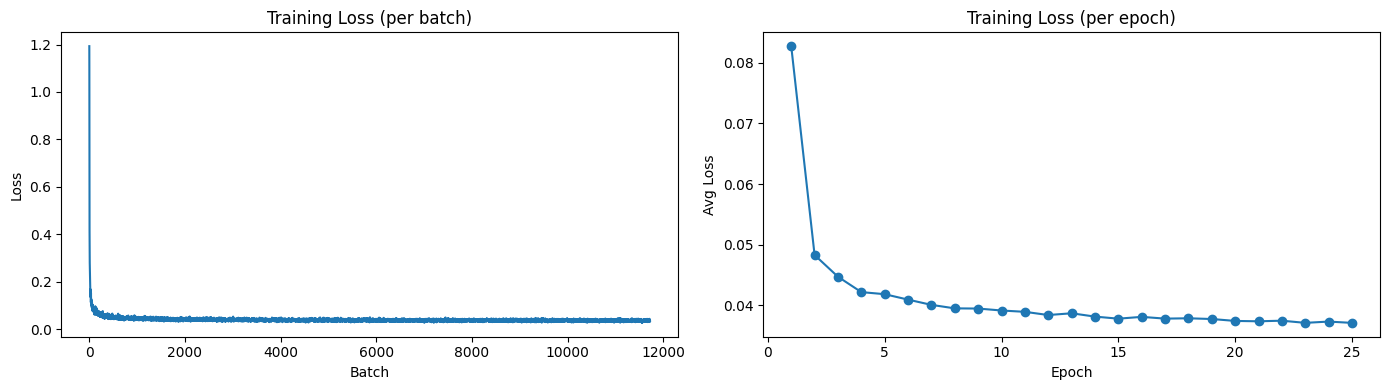

Loaded best model with loss: 0.037079


In [12]:
# Data loading — normalize to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x * 2) - 1)  # scale to [-1, 1]
])

mnist = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
dataloader = DataLoader(mnist, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

# TODO: Training loop
# Requirements:
#   - optimizer: Adam with lr=2e-4
#   - num_epochs: at least 10 (20+ for good results)
#   - sample uniformly random t in [0, T-1] for each batch
#   - track and plot training loss curve
#   - save best model checkpoint
model = UNet().to(device)
optimizer = Adam(model.parameters(), lr=2e-4)
num_epochs = 25
losses = []
best_loss = float('inf')
epoch_losses = []

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    num_batches = 0
    pbar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for x_0, _ in pbar:
        x_0 = x_0.to(device)
        t = torch.randint(0, T, (x_0.shape[0],), device=device).long()
        loss = loss_simple(model, x_0, t)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        num_batches += 1
        losses.append(loss.item())
        pbar.set_postfix(loss=loss.item())
    avg_loss = epoch_loss / num_batches
    epoch_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} — Avg Loss: {avg_loss:.6f}")
    if avg_loss < best_loss:
        best_loss = avg_loss
        torch.save(model.state_dict(), 'best_ddpm.pt')
        print(f"  -> Best model saved (loss={best_loss:.6f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(losses)
ax1.set_title('Training Loss (per batch)')
ax1.set_xlabel('Batch')
ax1.set_ylabel('Loss')
ax2.plot(range(1, num_epochs + 1), epoch_losses, marker='o')
ax2.set_title('Training Loss (per epoch)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Avg Loss')
plt.tight_layout()
plt.show()

model.load_state_dict(torch.load('best_ddpm.pt'))
model.eval()
print(f"Loaded best model with loss: {best_loss:.6f}")

## A.5 — DDPM Reverse Sampling

Implement the full DDPM reverse process:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon_\theta(x_t, t)\right) + \sqrt{\tilde{\beta}_t}\, z$$

where $z \sim \mathcal{N}(0, I)$ for $t > 1$ and $z = 0$ for $t = 1$.

**Requirements:**
1. Implement `p_sample(model, x_t, t)` — single reverse step.
2. Implement `p_sample_loop(model, shape)` — full loop from $x_T \sim \mathcal{N}(0,I)$ to $x_0$.
3. Generate a grid of 64 samples and display them.
4. Also implement `predict_x0_from_eps(x_t, t, eps)` that recovers $\hat{x}_0$ from the predicted noise, and visualize intermediate $\hat{x}_0$ predictions at timesteps $T, 0.75T, 0.5T, 0.25T, 0$.


Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

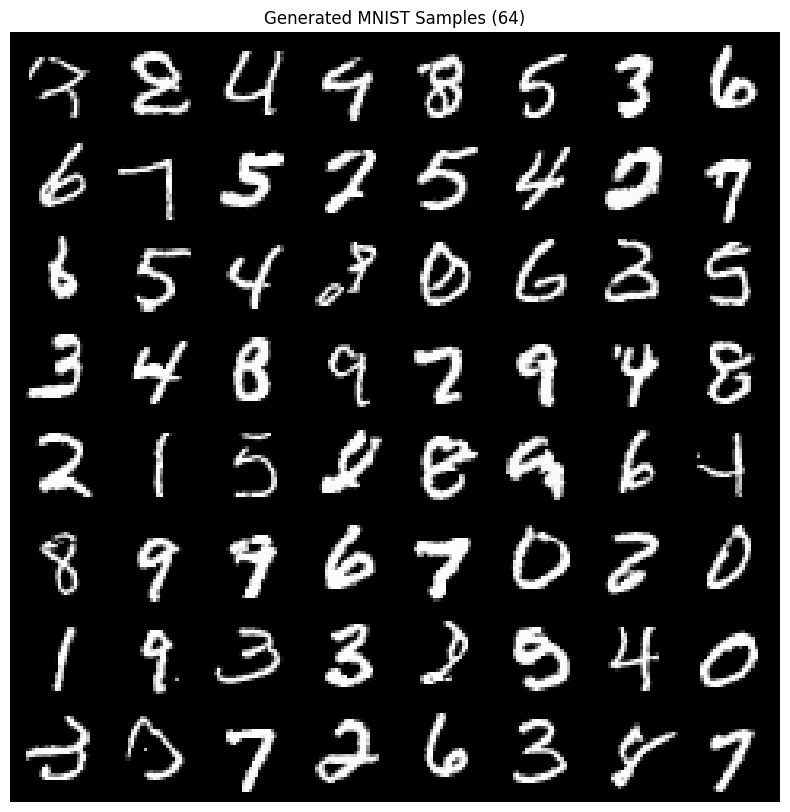

Sampling with x0 vis:   0%|          | 0/1000 [00:00<?, ?it/s]

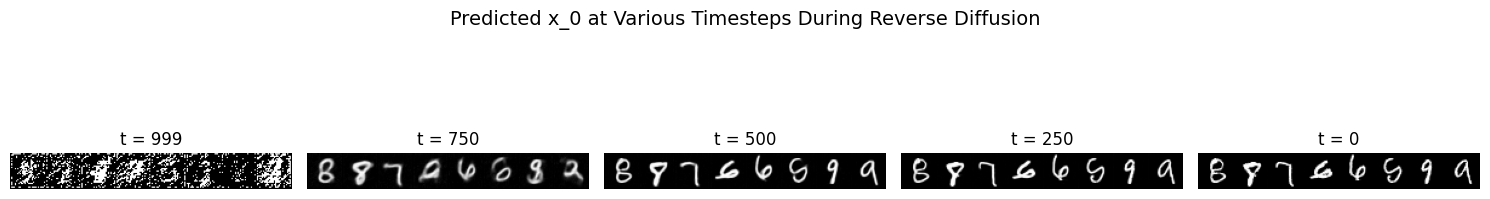

In [13]:
@torch.no_grad()
def p_sample(model, x_t, t_index):
    """
    TODO: One step of the reverse process.
    t_index: integer (not a batch tensor)
    Returns: x_{t-1}
    """
    b = x_t.shape[0]
    t_batch = torch.full((b,), t_index, device=x_t.device, dtype=torch.long)
    beta_t = extract(betas, t_batch, x_t.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t_batch, x_t.shape)
    sqrt_recip_alpha_t = extract(sqrt_recip_alphas, t_batch, x_t.shape)
    eps_pred = model(x_t, t_batch)
    model_mean = sqrt_recip_alpha_t * (x_t - (beta_t / sqrt_one_minus_alpha_hat_t) * eps_pred)
    if t_index == 0:
        return model_mean
    else:
        posterior_var_t = extract(posterior_variance, t_batch, x_t.shape)
        noise = torch.randn_like(x_t)
        return model_mean + torch.sqrt(posterior_var_t) * noise


@torch.no_grad()
def p_sample_loop(model, shape):
    """
    TODO: Full reverse process from x_T to x_0.
    shape: (B, C, H, W)
    Returns: final image tensor, shape (B, C, H, W)
    """
    device_used = next(model.parameters()).device
    x = torch.randn(shape, device=device_used)
    for t_index in tqdm(reversed(range(0, T)), total=T, desc='Sampling'):
        x = p_sample(model, x, t_index)
    return x


def predict_x0_from_eps(x_t, t, eps):
    """
    TODO: Recover the predicted x_0 given x_t, t, and predicted noise eps.
    """
    sqrt_alpha_hat_t = extract(sqrt_alpha_hats, t, x_t.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t, x_t.shape)
    x_0_pred = (x_t - sqrt_one_minus_alpha_hat_t * eps) / sqrt_alpha_hat_t
    return x_0_pred


# TODO: Generate and display 64 samples in an 8x8 grid
model.eval()
samples = p_sample_loop(model, shape=(64, 1, 28, 28))
samples_display = (samples.clamp(-1, 1) + 1) / 2
grid = make_grid(samples_display, nrow=8, padding=2)
plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
plt.axis('off')
plt.title('Generated MNIST Samples (64)')
plt.show()

# TODO: Visualize intermediate x_0 predictions during reverse diffusion
model.eval()
vis_steps = [T - 1, int(0.75 * T), int(0.5 * T), int(0.25 * T), 0]
num_vis = 8
device_used = next(model.parameters()).device
x = torch.randn(num_vis, 1, 28, 28, device=device_used)
x0_predictions = {}

for t_index in tqdm(reversed(range(0, T)), total=T, desc='Sampling with x0 vis'):
    t_batch = torch.full((num_vis,), t_index, device=device_used, dtype=torch.long)
    if t_index in vis_steps:
        eps_pred = model(x, t_batch)
        x0_pred = predict_x0_from_eps(x, t_batch, eps_pred)
        x0_predictions[t_index] = x0_pred.clone()
    x = p_sample(model, x, t_index)

x0_predictions[0] = x.clone()

fig, axes = plt.subplots(1, len(vis_steps), figsize=(3 * len(vis_steps), 3))
for i, step in enumerate(vis_steps):
    imgs = x0_predictions[step]
    imgs_display = (imgs.clamp(-1, 1) + 1) / 2
    grid_vis = make_grid(imgs_display, nrow=num_vis, padding=1)
    axes[i].imshow(grid_vis.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    axes[i].set_title(f't = {step}')
    axes[i].axis('off')
plt.suptitle('Predicted x_0 at Various Timesteps During Reverse Diffusion', fontsize=14)
plt.tight_layout()
plt.show()